# Q9 Practice: BTC10% SuperTrend Satellite Robustness And Underwater Experience

Q9 validates the Q8 candidate:

> Original three-asset RiskParity core + BTC 10% SuperTrend satellite.

The goal is not to find a prettier backtest. The goal is to answer:

1. Does BTC10% SuperTrend satellite depend on a magic parameter?
2. Does it improve the investor experience, especially underwater time and recovery quality, versus original RiskParity?
3. Is 10% a reasonable cap, or just another lucky setting?


## 1. Setup and Data Loading

BTC is sampled on the ETF common trading calendar. This keeps all metrics comparable to the original three-asset RiskParity baseline.


In [ ]:
# Keep relative research paths stable after this notebook moved.
import os
from xquant.project import find_repo_root

REPO_ROOT = find_repo_root()
os.chdir(REPO_ROOT)


In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

warnings.filterwarnings("ignore")

plt.rcParams["font.sans-serif"] = ["Arial Unicode MS", "SimHei", "STHeiti"]
plt.rcParams["axes.unicode_minus"] = False

OUTPUT_DIR = Path("outputs/q9-btc-supertrend-satellite-robustness")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CORE_SYMBOLS = ("510300.SS", "513100.SS", "518880.SS")
BTC_SYMBOL = "BTC-USD"
ALL_SYMBOLS = CORE_SYMBOLS + (BTC_SYMBOL,)
SYMBOL_NAMES = {
    "510300.SS": "沪深300ETF",
    "513100.SS": "纳指100ETF",
    "518880.SS": "黄金ETF",
    "BTC-USD": "BTC",
}
START = "2016-06-21"
INITIAL_CAPITAL = 100_000
TRADING_DAYS = 252
REBALANCE_DAYS = 10
VOL_WINDOW = 20
DEFAULT_ATR = 10
DEFAULT_MULTIPLIER = 3.0
DEFAULT_CAP = 0.10
PARAM_GRID = [(atr, mult) for atr in [7, 10, 14] for mult in [2.0, 3.0, 4.0]]
CAP_GRID = [0.05, 0.075, 0.10, 0.125, 0.15]


In [2]:
def _flatten_yfinance_columns(df, symbol):
    out = df.copy()
    if isinstance(out.columns, pd.MultiIndex):
        out.columns = [col[0] if col[1] == symbol else "_".join(map(str, col)).strip() for col in out.columns]
    out.columns = [str(c).lower().replace(" ", "_") for c in out.columns]
    return out


def download_symbol(symbol, start=START):
    df = yf.download(symbol, start=start, auto_adjust=True, progress=False, threads=False)
    if df.empty:
        raise RuntimeError(f"No data downloaded for {symbol}")
    df = _flatten_yfinance_columns(df, symbol)
    required = ["open", "high", "low", "close", "volume"]
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise RuntimeError(f"{symbol} missing columns: {missing}")
    df = df[required].dropna(subset=["open", "high", "low", "close"])
    df.index = pd.DatetimeIndex(df.index).tz_localize(None).normalize()
    return df

raw = {sym: download_symbol(sym) for sym in ALL_SYMBOLS}
etf_index = raw[CORE_SYMBOLS[0]].index
for sym in CORE_SYMBOLS[1:]:
    etf_index = etf_index.intersection(raw[sym].index)
etf_index = etf_index.sort_values()

data = {}
for sym in CORE_SYMBOLS:
    data[sym] = raw[sym].reindex(etf_index).dropna(subset=["close"])
btc_daily = raw[BTC_SYMBOL].sort_index().ffill()
data[BTC_SYMBOL] = btc_daily.reindex(etf_index, method="ffill").dropna(subset=["close"])

common_index = etf_index
for sym in ALL_SYMBOLS:
    common_index = common_index.intersection(data[sym].index)
common_index = common_index.sort_values()

data = {sym: data[sym].reindex(common_index).copy() for sym in ALL_SYMBOLS}
close = pd.DataFrame({sym: data[sym]["close"] for sym in ALL_SYMBOLS}).dropna()
open_ = pd.DataFrame({sym: data[sym]["open"] for sym in ALL_SYMBOLS}).reindex(close.index)
high = pd.DataFrame({sym: data[sym]["high"] for sym in ALL_SYMBOLS}).reindex(close.index)
low = pd.DataFrame({sym: data[sym]["low"] for sym in ALL_SYMBOLS}).reindex(close.index)
returns_cc = close.pct_change().fillna(0.0)
gap_returns = (open_ / close.shift(1) - 1.0).replace([np.inf, -np.inf], np.nan).fillna(0.0)
intraday_returns = (close / open_ - 1.0).replace([np.inf, -np.inf], np.nan).fillna(0.0)

print(f"共同样本: {close.index[0].date()} 到 {close.index[-1].date()}，{len(close)} 个ETF交易日")
for sym in ALL_SYMBOLS:
    print(f"{SYMBOL_NAMES[sym]}: {close[sym].iloc[-1] / close[sym].iloc[0] - 1:.2%}")


共同样本: 2016-06-21 到 2026-06-23，2426 个ETF交易日
沪深300ETF: 89.15%
纳指100ETF: 603.10%
黄金ETF: 214.79%
BTC: 9330.11%


## 2. Backtest And Strategy Helpers


In [3]:
def normalize_weights(w):
    weights = {sym: float(max(0.0, w.get(sym, 0.0))) for sym in ALL_SYMBOLS}
    total = sum(weights.values())
    if total > 1.0 + 1e-12:
        weights = {sym: val / total for sym, val in weights.items()}
        total = 1.0
    weights["CASH"] = max(0.0, 1.0 - total)
    return weights


def risk_parity_weight(date, eligible, vol_window=VOL_WINDOW):
    eligible = list(eligible)
    if not eligible:
        return normalize_weights({})
    loc = close.index.get_loc(date)
    if loc < vol_window:
        return normalize_weights({})
    hist = returns_cc.iloc[loc - vol_window + 1 : loc + 1][eligible]
    vols = hist.std(ddof=1).replace(0, np.nan).dropna()
    vols = vols[vols > 0]
    if vols.empty:
        return normalize_weights({})
    inv = 1.0 / vols
    return normalize_weights((inv / inv.sum()).to_dict())


def make_rebalance_mask(index, every=REBALANCE_DAYS):
    mask = pd.Series(False, index=index)
    mask.iloc[::every] = True
    return mask


def build_targets(allocator, rebalance_days=REBALANCE_DAYS):
    rebalance_mask = make_rebalance_mask(close.index, rebalance_days)
    rows = []
    last = normalize_weights({})
    for date in close.index:
        if bool(rebalance_mask.loc[date]):
            last = allocator(date)
        rows.append(last)
    targets = pd.DataFrame(rows, index=close.index).fillna(0.0)
    for col in list(ALL_SYMBOLS) + ["CASH"]:
        if col not in targets.columns:
            targets[col] = 0.0
    return targets[list(ALL_SYMBOLS) + ["CASH"]]


def backtest_targets(name, targets, execution="next_close", cost_bps=0.0):
    cost_rate = cost_bps / 10_000.0
    dates = close.index
    prev_weights = pd.Series(0.0, index=list(ALL_SYMBOLS) + ["CASH"])
    current_weights = prev_weights.copy()
    nav = []
    rets = []
    turnover = []
    costs = []
    held_rows = []
    value = INITIAL_CAPITAL

    for i, date in enumerate(dates):
        desired = targets.iloc[i - 1] if i > 0 else prev_weights
        desired = desired.reindex(prev_weights.index).fillna(0.0)

        if execution == "next_close":
            trade = (desired - current_weights).abs().sum() / 2.0
            gross = float((desired[list(ALL_SYMBOLS)] * returns_cc.loc[date, list(ALL_SYMBOLS)]).sum())
            cost = trade * cost_rate
            current_weights = desired.copy()
            day_ret = gross - cost
        elif execution == "next_open":
            gap = float((current_weights[list(ALL_SYMBOLS)] * gap_returns.loc[date, list(ALL_SYMBOLS)]).sum())
            value_after_gap = value * (1.0 + gap)
            trade = (desired - current_weights).abs().sum() / 2.0
            cost_cash = value_after_gap * trade * cost_rate
            value_after_trade = value_after_gap - cost_cash
            intraday = float((desired[list(ALL_SYMBOLS)] * intraday_returns.loc[date, list(ALL_SYMBOLS)]).sum())
            new_value = value_after_trade * (1.0 + intraday)
            day_ret = new_value / value - 1.0 if value > 0 else 0.0
            cost = cost_cash / value if value > 0 else 0.0
            current_weights = desired.copy()
        else:
            raise ValueError(execution)

        value *= (1.0 + day_ret)
        nav.append(value)
        rets.append(day_ret)
        turnover.append(float(trade))
        costs.append(float(cost))
        held_rows.append(current_weights.to_dict())

    return {
        "name": name,
        "nav": pd.Series(nav, index=dates, name=name),
        "returns": pd.Series(rets, index=dates, name=name),
        "targets": targets,
        "weights": pd.DataFrame(held_rows, index=dates).fillna(0.0),
        "turnover": pd.Series(turnover, index=dates, name=name),
        "costs": pd.Series(costs, index=dates, name=name),
        "execution": execution,
        "cost_bps": cost_bps,
    }


In [4]:
def true_range(high_s, low_s, close_s):
    prev_close = close_s.shift(1)
    parts = pd.concat([
        high_s - low_s,
        (high_s - prev_close).abs(),
        (low_s - prev_close).abs(),
    ], axis=1)
    return parts.max(axis=1)


def supertrend_signal_for_symbol(sym, atr_period=DEFAULT_ATR, multiplier=DEFAULT_MULTIPLIER):
    h = high[sym]
    l = low[sym]
    c = close[sym]
    atr = true_range(h, l, c).rolling(atr_period).mean()
    hl2 = (h + l) / 2.0
    basic_upper = hl2 + multiplier * atr
    basic_lower = hl2 - multiplier * atr

    final_upper = pd.Series(index=c.index, dtype=float)
    final_lower = pd.Series(index=c.index, dtype=float)
    st = pd.Series(index=c.index, dtype=float)
    bullish = pd.Series(False, index=c.index, dtype=bool)

    for i, date in enumerate(c.index):
        if pd.isna(atr.iloc[i]):
            continue
        if i == 0 or pd.isna(final_upper.iloc[i - 1]):
            final_upper.iloc[i] = basic_upper.iloc[i]
            final_lower.iloc[i] = basic_lower.iloc[i]
            st.iloc[i] = final_upper.iloc[i]
            bullish.iloc[i] = False
            continue
        prev_date = c.index[i - 1]
        final_upper.iloc[i] = basic_upper.iloc[i] if (basic_upper.iloc[i] < final_upper.iloc[i - 1] or c.loc[prev_date] > final_upper.iloc[i - 1]) else final_upper.iloc[i - 1]
        final_lower.iloc[i] = basic_lower.iloc[i] if (basic_lower.iloc[i] > final_lower.iloc[i - 1] or c.loc[prev_date] < final_lower.iloc[i - 1]) else final_lower.iloc[i - 1]
        if st.iloc[i - 1] == final_upper.iloc[i - 1]:
            st.iloc[i] = final_lower.iloc[i] if c.iloc[i] > final_upper.iloc[i] else final_upper.iloc[i]
        else:
            st.iloc[i] = final_upper.iloc[i] if c.iloc[i] < final_lower.iloc[i] else final_lower.iloc[i]
        bullish.iloc[i] = c.iloc[i] > st.iloc[i]
    return st, bullish

_ST_CACHE = {}
def btc_supertrend_signal(atr_period=DEFAULT_ATR, multiplier=DEFAULT_MULTIPLIER):
    key = (atr_period, float(multiplier))
    if key not in _ST_CACHE:
        _ST_CACHE[key] = supertrend_signal_for_symbol(BTC_SYMBOL, atr_period, multiplier)[1]
    return _ST_CACHE[key]

btc_ma200 = close[BTC_SYMBOL] > close[BTC_SYMBOL].rolling(200).mean()
print("Indicator helpers ready")


Indicator helpers ready


In [5]:
def core_rp_targets():
    def allocator(date):
        return risk_parity_weight(date, CORE_SYMBOLS, VOL_WINDOW)
    return build_targets(allocator)


def four_asset_rp_targets():
    def allocator(date):
        return risk_parity_weight(date, ALL_SYMBOLS, VOL_WINDOW)
    return build_targets(allocator)


def btc_satellite_targets(cap=DEFAULT_CAP, signal=None):
    def allocator(date):
        core = risk_parity_weight(date, CORE_SYMBOLS, VOL_WINDOW)
        weights = {sym: core.get(sym, 0.0) * (1.0 - cap) for sym in CORE_SYMBOLS}
        btc_on = True if signal is None else bool(signal.loc[date])
        weights[BTC_SYMBOL] = cap if btc_on else 0.0
        return normalize_weights(weights)
    return build_targets(allocator)


def run_core_rp(name="原三资产RiskParity", execution="next_close", cost_bps=0.0):
    return backtest_targets(name, core_rp_targets(), execution=execution, cost_bps=cost_bps)


def run_four_rp(name="四资产普通RiskParity", execution="next_close", cost_bps=0.0):
    return backtest_targets(name, four_asset_rp_targets(), execution=execution, cost_bps=cost_bps)


def run_btc_satellite(name, cap=DEFAULT_CAP, signal=None, execution="next_close", cost_bps=0.0):
    return backtest_targets(name, btc_satellite_targets(cap, signal), execution=execution, cost_bps=cost_bps)


def run_btc_st_satellite(cap=DEFAULT_CAP, atr=DEFAULT_ATR, multiplier=DEFAULT_MULTIPLIER, name=None, execution="next_close", cost_bps=0.0):
    if name is None:
        name = f"BTC{cap:.1%}_ST{atr}_{multiplier:g}卫星"
    return run_btc_satellite(name, cap=cap, signal=btc_supertrend_signal(atr, multiplier), execution=execution, cost_bps=cost_bps)


## 3. Metrics: Monthly, Underwater, Recovery, Relative Comparison


In [6]:
def drawdown(nav_s):
    return nav_s / nav_s.cummax() - 1.0


def strategy_metrics(result):
    nav_s = result["nav"].dropna()
    ret_s = result["returns"].reindex(nav_s.index).fillna(0.0)
    total = nav_s.iloc[-1] / nav_s.iloc[0] - 1.0
    annual = (nav_s.iloc[-1] / nav_s.iloc[0]) ** (TRADING_DAYS / (len(nav_s) - 1)) - 1.0
    vol = ret_s.std(ddof=1) * np.sqrt(TRADING_DAYS)
    max_dd = drawdown(nav_s).min()
    sharpe = (ret_s.mean() * TRADING_DAYS) / vol if vol > 0 else np.nan
    calmar = annual / abs(max_dd) if max_dd < 0 else np.nan
    downside = ret_s[ret_s < 0]
    downside_dev = np.sqrt((downside ** 2).mean()) * np.sqrt(TRADING_DAYS) if len(downside) else np.nan
    sortino = (ret_s.mean() * TRADING_DAYS) / downside_dev if downside_dev and downside_dev > 0 else np.nan
    weights = result["weights"].reindex(nav_s.index).fillna(0.0)
    turnover = result["turnover"].reindex(nav_s.index).fillna(0.0)
    costs = result["costs"].reindex(nav_s.index).fillna(0.0)
    row = {
        "累计收益": total,
        "年化收益": annual,
        "年化波动": vol,
        "最大回撤": max_dd,
        "夏普": sharpe,
        "卡玛": calmar,
        "索提诺": sortino,
        "平均现金": weights["CASH"].mean(),
        "年化换手": turnover.mean() * TRADING_DAYS,
        "成本拖累": costs.sum(),
    }
    for sym in ALL_SYMBOLS:
        row[f"平均权重_{SYMBOL_NAMES[sym]}"] = weights[sym].mean()
        row[f"当前权重_{SYMBOL_NAMES[sym]}"] = weights[sym].iloc[-1]
    return row


def monthly_returns(nav_s):
    month_end = nav_s.resample("ME").last()
    return month_end.pct_change().dropna()


def annual_returns(nav_s):
    year_end = nav_s.resample("YE").last()
    prev = pd.concat([pd.Series([nav_s.iloc[0]], index=[nav_s.index[0]]), year_end])
    out = prev.pct_change().dropna()
    out.index = out.index.year
    return out


def max_consecutive(mask):
    longest = 0
    current = 0
    for value in mask:
        if bool(value):
            current += 1
            longest = max(longest, current)
        else:
            current = 0
    return longest


def monthly_stats(result):
    months = monthly_returns(result["nav"])
    gains = months[months > 0]
    losses = months[months < 0]
    total_gain = gains.sum()
    total_loss = losses.sum()
    avg_gain = gains.mean() if len(gains) else 0.0
    avg_loss = losses.mean() if len(losses) else 0.0
    return {
        "总月数": len(months),
        "盈利月数": len(gains),
        "亏损月数": len(losses),
        "月度胜率": len(gains) / len(months) if len(months) else np.nan,
        "平均盈利月": avg_gain,
        "平均亏损月": avg_loss,
        "盈亏比": avg_gain / abs(avg_loss) if avg_loss != 0 else np.nan,
        "盈亏因子": total_gain / abs(total_loss) if total_loss != 0 else np.nan,
        "最好月": months.max() if len(months) else np.nan,
        "最差月": months.min() if len(months) else np.nan,
        "最长连赢": max_consecutive(months > 0),
        "最长连亏": max_consecutive(months < 0),
    }


def underwater_stats(result):
    dd = drawdown(result["nav"]).dropna()
    underwater = dd < 0
    current_run = 0
    for value in reversed(underwater.tolist()):
        if value:
            current_run += 1
        else:
            break
    return {
        "水下时间占比": underwater.mean(),
        "平均水下": dd[underwater].mean() if underwater.any() else 0.0,
        "中位数水下": dd[underwater].median() if underwater.any() else 0.0,
        "最长水下天数": max_consecutive(underwater),
        "超过-5%天数": int((dd <= -0.05).sum()),
        "超过-10%天数": int((dd <= -0.10).sum()),
        "超过-15%天数": int((dd <= -0.15).sum()),
        "超过-10%时间占比": float((dd <= -0.10).mean()),
        "当前是否水下": bool(dd.iloc[-1] < 0),
        "当前水下深度": float(dd.iloc[-1]),
        "当前水下已持续天数": current_run,
    }


def drawdown_events(result):
    dd = drawdown(result["nav"]).dropna()
    events = []
    in_dd = False
    start = trough = None
    trough_value = 0.0
    for date, value in dd.items():
        if not in_dd and value < 0:
            in_dd = True
            start = trough = date
            trough_value = value
        elif in_dd:
            if value < trough_value:
                trough = date
                trough_value = value
            if value >= 0:
                events.append({
                    "开始日期": pd.Timestamp(start).date(),
                    "最低点日期": pd.Timestamp(trough).date(),
                    "恢复日期": pd.Timestamp(date).date(),
                    "深度": trough_value,
                    "下跌天数": (pd.Timestamp(trough) - pd.Timestamp(start)).days,
                    "恢复天数": (pd.Timestamp(date) - pd.Timestamp(trough)).days,
                    "总持续天数": (pd.Timestamp(date) - pd.Timestamp(start)).days,
                })
                in_dd = False
                start = trough = None
                trough_value = 0.0
    if in_dd and start is not None:
        last = dd.index[-1]
        events.append({
            "开始日期": pd.Timestamp(start).date(),
            "最低点日期": pd.Timestamp(trough).date(),
            "恢复日期": "未恢复",
            "深度": trough_value,
            "下跌天数": (pd.Timestamp(trough) - pd.Timestamp(start)).days,
            "恢复天数": np.nan,
            "总持续天数": (pd.Timestamp(last) - pd.Timestamp(start)).days,
        })
    return pd.DataFrame(events).sort_values("深度") if events else pd.DataFrame()


def recovery_stats(result):
    events = drawdown_events(result)
    if events.empty:
        return {"回撤次数": 0}
    recovery_numeric = pd.to_numeric(events["恢复天数"], errors="coerce")
    recovered = events[recovery_numeric.notna()].copy()
    unresolved = events[recovery_numeric.isna()].copy()
    row = {
        "回撤次数": len(events),
        "已修复回撤次数": len(recovered),
        "未修复回撤次数": len(unresolved),
        "平均回撤深度": events["深度"].mean(),
        "最大回撤": events["深度"].min(),
        "平均修复天数": recovered["恢复天数"].mean() if len(recovered) else np.nan,
        "中位数修复天数": recovered["恢复天数"].median() if len(recovered) else np.nan,
        "最长修复天数": recovered["恢复天数"].max() if len(recovered) else np.nan,
        "最长总持续天数": events["总持续天数"].max(),
        "最深回撤深度": events.iloc[0]["深度"],
        "最深回撤开始": events.iloc[0]["开始日期"],
        "最深回撤最低点": events.iloc[0]["最低点日期"],
        "最深回撤恢复": events.iloc[0]["恢复日期"],
    }
    if len(unresolved):
        current = unresolved.iloc[-1]
        row["未修复回撤深度"] = current["深度"]
        row["未修复已持续天数"] = current["总持续天数"]
    else:
        row["未修复回撤深度"] = 0.0
        row["未修复已持续天数"] = 0
    return row


## 4. Main Candidate Set


In [7]:
main_results = {
    "原三资产RiskParity": run_core_rp(),
    "四资产普通RiskParity": run_four_rp(),
    "BTC10%MA200卫星": run_btc_satellite("BTC10%MA200卫星", cap=0.10, signal=btc_ma200),
    "BTC5%SuperTrend卫星": run_btc_st_satellite(cap=0.05, atr=DEFAULT_ATR, multiplier=DEFAULT_MULTIPLIER, name="BTC5%SuperTrend卫星"),
    "BTC10%SuperTrend卫星": run_btc_st_satellite(cap=0.10, atr=DEFAULT_ATR, multiplier=DEFAULT_MULTIPLIER, name="BTC10%SuperTrend卫星"),
    "BTC15%SuperTrend卫星": run_btc_st_satellite(cap=0.15, atr=DEFAULT_ATR, multiplier=DEFAULT_MULTIPLIER, name="BTC15%SuperTrend卫星"),
}

q3_metrics = pd.DataFrame({name: strategy_metrics(result) for name, result in main_results.items()}).T
q5_metrics = q3_metrics[["累计收益", "年化收益", "年化波动", "最大回撤", "夏普", "卡玛", "索提诺", "平均现金", "年化换手", "成本拖累"]].copy()
q5_metrics["Alpha_vs_RP基准"] = q5_metrics["累计收益"] - q5_metrics.loc["原三资产RiskParity", "累计收益"]
monthly_table = pd.DataFrame({name: monthly_stats(result) for name, result in main_results.items()}).T
underwater_table = pd.DataFrame({name: underwater_stats(result) for name, result in main_results.items()}).T
recovery_table = pd.DataFrame({name: recovery_stats(result) for name, result in main_results.items()}).T
annual_table = pd.DataFrame({name: annual_returns(result["nav"]) for name, result in main_results.items()})
nav_table = pd.DataFrame({name: result["nav"] for name, result in main_results.items()})
underwater_curves = nav_table.apply(drawdown)

q3_metrics.to_csv(OUTPUT_DIR / "q3_metrics.csv", encoding="utf-8-sig")
q5_metrics.join(monthly_table).to_csv(OUTPUT_DIR / "q5_metrics.csv", encoding="utf-8-sig")
monthly_table.to_csv(OUTPUT_DIR / "monthly_stats.csv", encoding="utf-8-sig")
underwater_table.to_csv(OUTPUT_DIR / "underwater_stats.csv", encoding="utf-8-sig")
recovery_table.to_csv(OUTPUT_DIR / "recovery_stats.csv", encoding="utf-8-sig")
annual_table.to_csv(OUTPUT_DIR / "annual_returns.csv", encoding="utf-8-sig")
nav_table.to_csv(OUTPUT_DIR / "nav_main_candidates.csv", encoding="utf-8-sig")
underwater_curves.to_csv(OUTPUT_DIR / "underwater_curves.csv", encoding="utf-8-sig")
for name, result in main_results.items():
    drawdown_events(result).head(10).to_csv(OUTPUT_DIR / f"drawdown_events_{name}.csv", encoding="utf-8-sig", index=False)

q5_metrics.join(monthly_table).round(4)


,累计收益,年化收益,年化波动,最大回撤,夏普,卡玛,索提诺,平均现金,年化换手,成本拖累,...,亏损月数,月度胜率,平均盈利月,平均亏损月,盈亏比,盈亏因子,最好月,最差月,最长连赢,最长连亏
原三资产RiskParity,3.0715,0.1571,0.1122,-0.1353,1.3561,1.1609,1.2769,0.0082,1.9813,0.0,...,42.0,0.6500,0.0278,-0.0168,1.6559,3.0753,0.0922,-0.0750,11.0,4.0
四资产普通RiskParity,4.4869,0.1935,0.1199,-0.1744,1.5360,1.1094,1.4363,0.0082,2.1207,0.0,...,35.0,0.7083,0.0312,-0.0247,1.2629,3.0671,0.1195,-0.0773,19.0,5.0
BTC10%MA200卫星,5.3245,0.2113,0.1158,-0.1468,1.7137,1.4392,1.6790,0.0460,1.9546,0.0,...,41.0,0.6583,0.0334,-0.0175,1.9139,3.6878,0.1105,-0.0676,8.0,6.0
BTC5%SuperTrend卫星,4.0110,0.1823,0.1095,-0.1293,1.5840,1.4096,1.5052,0.0306,2.2069,0.0,...,39.0,0.6750,0.0288,-0.0168,1.7095,3.5505,0.0979,-0.0713,8.0,4.0
BTC10%SuperTrend卫星,5.1293,0.2073,0.1126,-0.1281,1.7299,1.6179,1.6712,0.0530,2.4324,0.0,...,38.0,0.6833,0.0312,-0.0178,1.7583,3.7942,0.1105,-0.0676,8.0,6.0
BTC15%SuperTrend卫星,6.4511,0.2321,0.1210,-0.1500,1.7856,1.5468,1.7648,0.0753,2.6579,0.0,...,40.0,0.6667,0.0357,-0.0189,1.8849,3.7699,0.1288,-0.0690,8.0,6.0


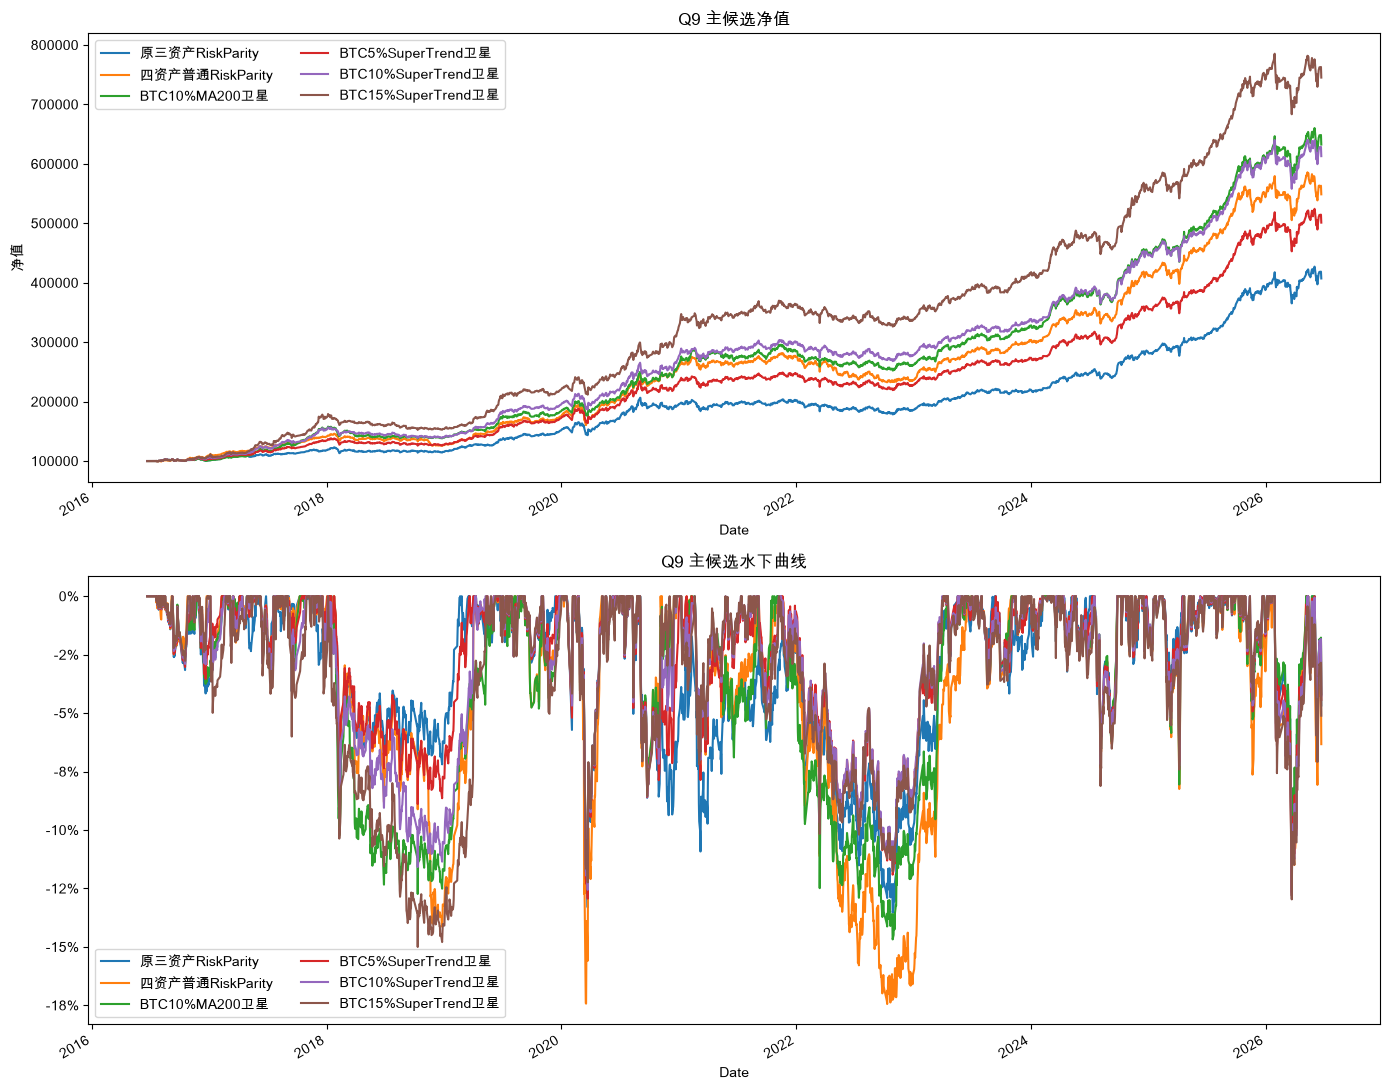

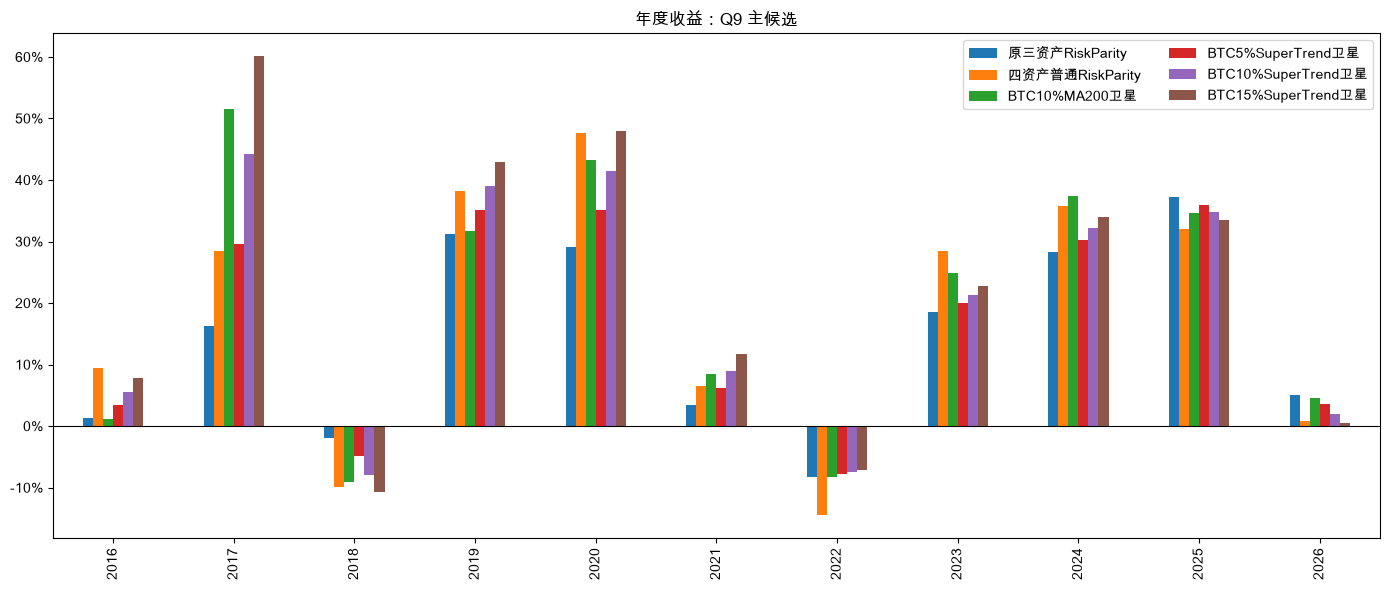

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(14, 11))
nav_table.plot(ax=axes[0])
axes[0].set_title("Q9 主候选净值")
axes[0].set_ylabel("净值")
axes[0].legend(loc="best", ncol=2)
underwater_curves.plot(ax=axes[1])
axes[1].set_title("Q9 主候选水下曲线")
axes[1].yaxis.set_major_formatter(lambda x, pos: f"{x:.0%}")
axes[1].legend(loc="best", ncol=2)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "main_nav_underwater.png", dpi=160)
plt.show()

fig, ax = plt.subplots(figsize=(14, 6))
annual_table.plot(kind="bar", ax=ax)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("年度收益：Q9 主候选")
ax.yaxis.set_major_formatter(lambda x, pos: f"{x:.0%}")
ax.legend(loc="best", ncol=2)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "annual_returns.png", dpi=160)
plt.show()


## 5. Relative Comparison Versus Original RiskParity

This is the direct answer to whether BTC10% SuperTrend improves the holding experience.


In [9]:
def comparison_pack(name):
    return {
        **q5_metrics.loc[name].to_dict(),
        **monthly_table.loc[name].add_prefix("月度_").to_dict(),
        **underwater_table.loc[name].add_prefix("水下_").to_dict(),
        **recovery_table.loc[name].add_prefix("修复_").to_dict(),
        "最差年": annual_table[name].min(),
    }

rp_pack = comparison_pack("原三资产RiskParity")
relative_rows = []
for name in main_results:
    pack = comparison_pack(name)
    row = {"策略": name}
    for key, value in pack.items():
        row[key] = value
        if isinstance(value, (int, float, np.integer, np.floating)) and key in rp_pack:
            row[f"差异_{key}"] = value - rp_pack[key]
    relative_rows.append(row)
relative_comparison = pd.DataFrame(relative_rows).set_index("策略")
relative_comparison.to_csv(OUTPUT_DIR / "relative_comparison_vs_rp.csv", encoding="utf-8-sig")

focus_cols = [
    "年化收益", "差异_年化收益", "最大回撤", "差异_最大回撤", "夏普", "差异_夏普", "卡玛", "差异_卡玛",
    "月度_月度胜率", "差异_月度_月度胜率", "月度_最差月", "差异_月度_最差月", "最差年", "差异_最差年",
    "水下_水下时间占比", "差异_水下_水下时间占比", "水下_平均水下", "差异_水下_平均水下", "水下_最长水下天数", "差异_水下_最长水下天数", "水下_超过-10%天数", "差异_水下_超过-10%天数",
    "修复_平均修复天数", "差异_修复_平均修复天数", "修复_最长修复天数", "差异_修复_最长修复天数", "修复_未修复回撤深度",
]
relative_comparison[focus_cols].round(4)


,年化收益,差异_年化收益,最大回撤,差异_最大回撤,夏普,差异_夏普,卡玛,差异_卡玛,月度_月度胜率,差异_月度_月度胜率,...,差异_水下_平均水下,水下_最长水下天数,差异_水下_最长水下天数,水下_超过-10%天数,差异_水下_超过-10%天数,修复_平均修复天数,差异_修复_平均修复天数,修复_最长修复天数,差异_修复_最长修复天数,修复_未修复回撤深度
策略,,,,,,,,,,,,,,,,,,,,,
原三资产RiskParity,0.1571,0.0000,-0.1353,0.0000,1.3561,0.0000,1.1609,0.0000,0.6500,0.0000,...,0.0000,653,0,83,0,12.4044,0.0000,376.0,0.0,-0.0699
四资产普通RiskParity,0.1935,0.0364,-0.1744,-0.0391,1.5360,0.1799,1.1094,-0.0515,0.7083,0.0583,...,-0.0075,381,-272,266,183,12.0556,-0.3489,248.0,-128.0,-0.0807
BTC10%MA200卫星,0.2113,0.0542,-0.1468,-0.0115,1.7137,0.3576,1.4392,0.2783,0.6583,0.0083,...,-0.0068,345,-308,345,262,12.4384,0.0339,242.0,-134.0,-0.0631
BTC5%SuperTrend卫星,0.1823,0.0252,-0.1293,0.0060,1.5840,0.2280,1.4096,0.2488,0.6750,0.0250,...,0.0047,332,-321,42,-41,10.6289,-1.7755,161.0,-215.0,-0.0665
BTC10%SuperTrend卫星,0.2073,0.0502,-0.1281,0.0072,1.7299,0.3738,1.6179,0.4571,0.6833,0.0333,...,0.0017,334,-319,89,6,11.1299,-1.2745,179.0,-197.0,-0.0636
BTC15%SuperTrend卫星,0.2321,0.0750,-0.1500,-0.0147,1.7856,0.4295,1.5468,0.3859,0.6667,0.0167,...,-0.0046,341,-312,220,137,10.7000,-1.7044,214.0,-162.0,-0.1297


## 6. BTC SuperTrend Parameter Grid

This directly tests whether `ATR10 / multiplier3` is a magic parameter.


In [10]:
param_rows = []
param_results = {}
for atr, mult in PARAM_GRID:
    name = f"BTC10%ST{atr}_{mult:g}卫星"
    result = run_btc_st_satellite(cap=DEFAULT_CAP, atr=atr, multiplier=mult, name=name)
    param_results[(atr, mult)] = result
    row = strategy_metrics(result)
    row.update(monthly_stats(result))
    row.update({f"水下_{k}": v for k, v in underwater_stats(result).items()})
    row["atr"] = atr
    row["multiplier"] = mult
    row["策略"] = name
    row["最差年"] = annual_returns(result["nav"]).min()
    row["是否默认参数"] = (atr == DEFAULT_ATR and float(mult) == DEFAULT_MULTIPLIER)
    param_rows.append(row)
param_grid = pd.DataFrame(param_rows)
param_grid["Calmar排名"] = param_grid["卡玛"].rank(ascending=False, method="min")
param_grid["Sharpe排名"] = param_grid["夏普"].rank(ascending=False, method="min")
param_grid.to_csv(OUTPUT_DIR / "btc_supertrend_parameter_grid.csv", encoding="utf-8-sig", index=False)

print("BTC10% SuperTrend parameter grid")
param_grid[["atr", "multiplier", "累计收益", "年化收益", "最大回撤", "夏普", "卡玛", "最差月", "最差年", "水下_水下时间占比", "水下_超过-10%天数", "Calmar排名", "Sharpe排名", "是否默认参数"]].sort_values("卡玛", ascending=False).round(4)


BTC10% SuperTrend parameter grid


,atr,multiplier,累计收益,年化收益,最大回撤,夏普,卡玛,最差月,最差年,水下_水下时间占比,水下_超过-10%天数,Calmar排名,Sharpe排名,是否默认参数
0,7,2.0,5.2975,0.2107,-0.1233,1.7843,1.7088,-0.0748,-0.0807,0.8351,54,1.0,1.0,False
7,14,3.0,5.1777,0.2083,-0.1256,1.7416,1.6588,-0.0676,-0.0755,0.8359,69,2.0,5.0,False
1,7,3.0,5.2250,0.2093,-0.1281,1.7374,1.6331,-0.0676,-0.0788,0.8376,83,3.0,6.0,False
4,10,3.0,5.1293,0.2073,-0.1281,1.7299,1.6179,-0.0676,-0.0788,0.8339,89,4.0,7.0,True
6,14,2.0,5.0996,0.2067,-0.1279,1.7498,1.6167,-0.0748,-0.0875,0.8364,61,5.0,4.0,False
3,10,2.0,4.9042,0.2026,-0.1256,1.7169,1.6136,-0.0676,-0.0875,0.8380,50,6.0,8.0,False
8,14,4.0,5.3973,0.2127,-0.1326,1.7543,1.6043,-0.0676,-0.0764,0.8355,95,7.0,3.0,False
5,10,4.0,5.4987,0.2147,-0.1376,1.7628,1.5604,-0.0676,-0.0922,0.8368,145,8.0,2.0,False
2,7,4.0,5.0894,0.2065,-0.1353,1.7151,1.5269,-0.0676,-0.0793,0.8425,110,9.0,9.0,False


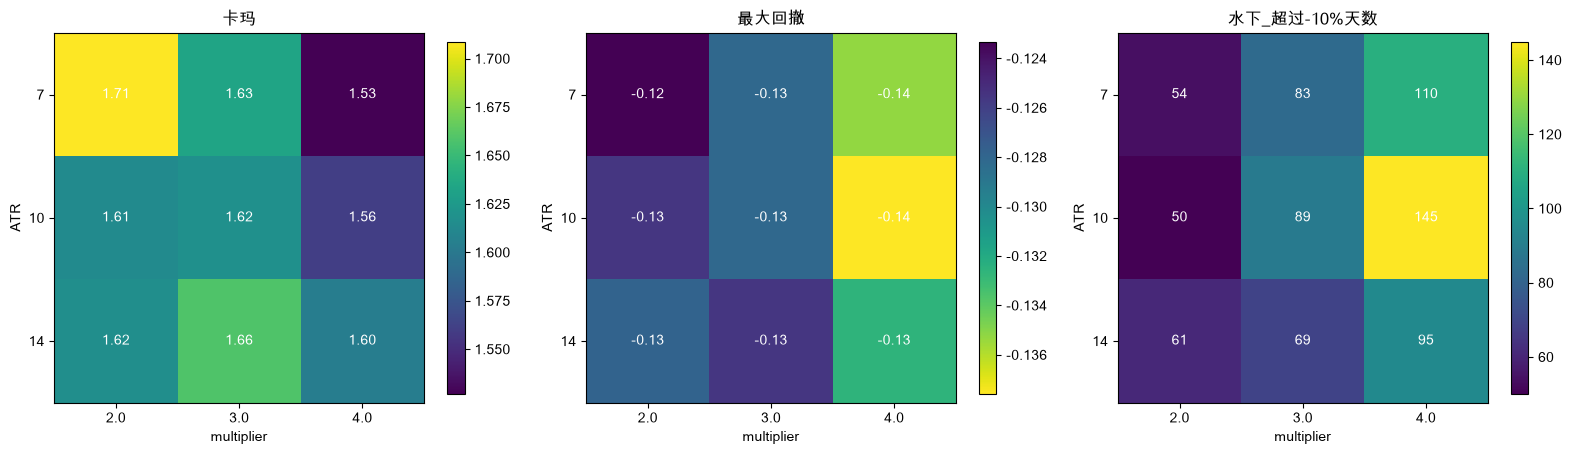

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for metric, ax in [("卡玛", axes[0]), ("最大回撤", axes[1]), ("水下_超过-10%天数", axes[2])]:
    pivot = param_grid.pivot(index="atr", columns="multiplier", values=metric)
    im = ax.imshow(pivot.values, cmap="viridis_r" if metric == "最大回撤" else "viridis")
    ax.set_title(metric)
    ax.set_xticks(range(len(pivot.columns)), labels=[str(c) for c in pivot.columns])
    ax.set_yticks(range(len(pivot.index)), labels=[str(i) for i in pivot.index])
    ax.set_xlabel("multiplier")
    ax.set_ylabel("ATR")
    for i in range(len(pivot.index)):
        for j in range(len(pivot.columns)):
            val = pivot.values[i, j]
            label = f"{val:.2f}" if metric != "水下_超过-10%天数" else f"{val:.0f}"
            ax.text(j, i, label, ha="center", va="center", color="white")
    fig.colorbar(im, ax=ax, shrink=0.75)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "btc_supertrend_parameter_heatmaps.png", dpi=160)
plt.show()


## 7. Cap Grid And Combined Cap/Parameter Grid

This tests whether 10% is a magic cap. We also run a compact combined grid to see whether the result survives nearby caps and parameters.


In [12]:
cap_rows = []
for cap in CAP_GRID:
    result = run_btc_st_satellite(cap=cap, atr=DEFAULT_ATR, multiplier=DEFAULT_MULTIPLIER, name=f"BTC{cap:.1%}ST10_3卫星")
    row = strategy_metrics(result)
    row.update(monthly_stats(result))
    row.update({f"水下_{k}": v for k, v in underwater_stats(result).items()})
    row["cap"] = cap
    row["策略"] = result["name"]
    row["最差年"] = annual_returns(result["nav"]).min()
    cap_rows.append(row)
cap_grid = pd.DataFrame(cap_rows)
cap_grid.to_csv(OUTPUT_DIR / "btc_supertrend_cap_grid.csv", encoding="utf-8-sig", index=False)

combo_rows = []
for cap in CAP_GRID:
    for atr, mult in PARAM_GRID:
        result = run_btc_st_satellite(cap=cap, atr=atr, multiplier=mult, name=f"BTC{cap:.1%}ST{atr}_{mult:g}卫星")
        row = strategy_metrics(result)
        row.update({f"水下_{k}": v for k, v in underwater_stats(result).items()})
        row["cap"] = cap
        row["atr"] = atr
        row["multiplier"] = mult
        row["最差年"] = annual_returns(result["nav"]).min()
        row["通过核心门槛"] = (
            row["年化收益"] > q5_metrics.loc["原三资产RiskParity", "年化收益"] and
            row["卡玛"] >= q5_metrics.loc["原三资产RiskParity", "卡玛"] and
            row["最大回撤"] >= q5_metrics.loc["原三资产RiskParity", "最大回撤"] and
            row["水下_超过-10%天数"] <= underwater_table.loc["原三资产RiskParity", "超过-10%天数"]
        )
        combo_rows.append(row)
combo_grid = pd.DataFrame(combo_rows)
combo_grid.to_csv(OUTPUT_DIR / "btc_supertrend_cap_parameter_grid.csv", encoding="utf-8-sig", index=False)

cap_summary = combo_grid.groupby("cap").agg(
    参数组合数=("卡玛", "count"),
    通过核心门槛数=("通过核心门槛", "sum"),
    平均卡玛=("卡玛", "mean"),
    最低卡玛=("卡玛", "min"),
    最高卡玛=("卡玛", "max"),
    平均最大回撤=("最大回撤", "mean"),
    平均超过负10天数=("水下_超过-10%天数", "mean"),
).reset_index()
cap_summary["通过率"] = cap_summary["通过核心门槛数"] / cap_summary["参数组合数"]
cap_summary.to_csv(OUTPUT_DIR / "btc_supertrend_cap_parameter_summary.csv", encoding="utf-8-sig", index=False)

print("Default parameter cap grid")
display(cap_grid[["cap", "累计收益", "年化收益", "最大回撤", "夏普", "卡玛", "水下_水下时间占比", "水下_超过-10%天数", "最差月", "最差年"]].round(4))
print("Combined cap/parameter summary")
display(cap_summary.round(4))


Default parameter cap grid


,cap,累计收益,年化收益,最大回撤,夏普,卡玛,水下_水下时间占比,水下_超过-10%天数,最差月,最差年
0,0.050,4.0110,0.1823,-0.1293,1.5840,1.4096,0.8289,42,-0.0713,-0.0784
1,0.075,4.5463,0.1949,-0.1275,1.6687,1.5288,0.8310,39,-0.0695,-0.0767
2,0.100,5.1293,0.2073,-0.1281,1.7299,1.6179,0.8339,89,-0.0676,-0.0788
3,0.125,5.7632,0.2197,-0.1331,1.7680,1.6512,0.8401,149,-0.0680,-0.0933
4,0.150,6.4511,0.2321,-0.1500,1.7856,1.5468,0.8442,220,-0.0690,-0.1076


Combined cap/parameter summary


,cap,参数组合数,通过核心门槛数,平均卡玛,最低卡玛,最高卡玛,平均最大回撤,平均超过负10天数,通过率
0,0.050,9,9,1.4176,1.3915,1.4509,-0.1291,47.3333,1.0000
1,0.075,9,8,1.5280,1.4802,1.5966,-0.1283,50.2222,0.8889
2,0.100,9,5,1.6156,1.5269,1.7088,-0.1293,84.0000,0.5556
3,0.125,9,3,1.6681,1.5580,1.7763,-0.1330,154.6667,0.3333
4,0.150,9,0,1.6638,1.5468,1.8398,-0.1414,209.3333,0.0000


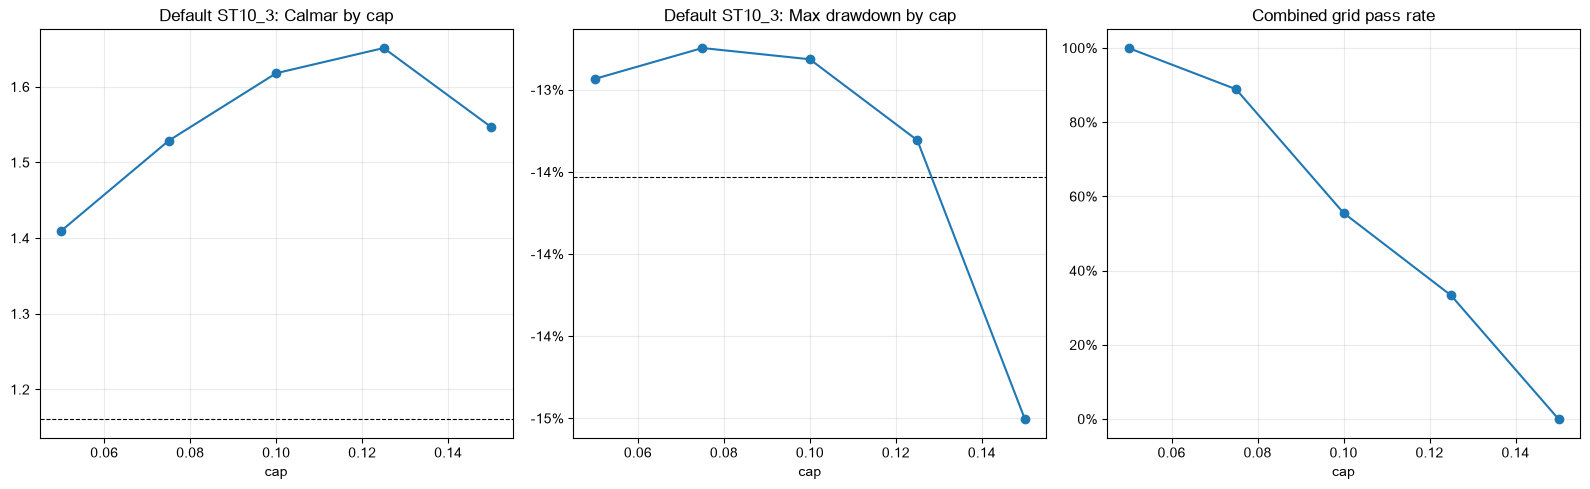

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
cap_grid.plot(x="cap", y="卡玛", marker="o", ax=axes[0], legend=False, title="Default ST10_3: Calmar by cap")
axes[0].axhline(q5_metrics.loc["原三资产RiskParity", "卡玛"], color="black", linestyle="--", linewidth=0.8)
cap_grid.plot(x="cap", y="最大回撤", marker="o", ax=axes[1], legend=False, title="Default ST10_3: Max drawdown by cap")
axes[1].axhline(q5_metrics.loc["原三资产RiskParity", "最大回撤"], color="black", linestyle="--", linewidth=0.8)
cap_summary.plot(x="cap", y="通过率", marker="o", ax=axes[2], legend=False, title="Combined grid pass rate")
for ax in axes:
    ax.grid(True, alpha=0.25)
axes[1].yaxis.set_major_formatter(lambda x, pos: f"{x:.0%}")
axes[2].yaxis.set_major_formatter(lambda x, pos: f"{x:.0%}")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "cap_grid_summary.png", dpi=160)
plt.show()


## 8. Rolling Windows And Train/Test


In [14]:
def slice_result(result, start=None, end=None):
    nav = result["nav"].loc[start:end]
    ret = result["returns"].loc[start:end]
    weights = result["weights"].loc[start:end]
    turnover = result["turnover"].loc[start:end]
    costs = result["costs"].loc[start:end]
    nav = nav / nav.iloc[0] * INITIAL_CAPITAL
    return {**result, "nav": nav, "returns": ret, "weights": weights, "turnover": turnover, "costs": costs}

windows = [
    ("2016H2-2020", "2016-06-21", "2020-12-31"),
    ("2017-2021", "2017-01-01", "2021-12-31"),
    ("2018-2022", "2018-01-01", "2022-12-31"),
    ("2019-2023", "2019-01-01", "2023-12-31"),
    ("2020-2024", "2020-01-01", "2024-12-31"),
    ("2021-2025", "2021-01-01", "2025-12-31"),
    ("2022-YTD", "2022-01-01", str(close.index[-1].date())),
]
rolling_names = ["原三资产RiskParity", "BTC5%SuperTrend卫星", "BTC10%SuperTrend卫星", "BTC15%SuperTrend卫星", "BTC10%MA200卫星", "四资产普通RiskParity"]
rolling_rows = []
for label, start, end in windows:
    rp_metrics = strategy_metrics(slice_result(main_results["原三资产RiskParity"], start, end))
    rp_underwater = underwater_stats(slice_result(main_results["原三资产RiskParity"], start, end))
    for name in rolling_names:
        sliced = slice_result(main_results[name], start, end)
        m = strategy_metrics(sliced)
        u = underwater_stats(sliced)
        row = {"窗口": label, "策略": name, **m, **{f"水下_{k}": v for k, v in u.items()}}
        row["收益跑赢RP"] = m["累计收益"] > rp_metrics["累计收益"]
        row["Calmar跑赢RP"] = m["卡玛"] > rp_metrics["卡玛"]
        row["回撤不深于RP"] = m["最大回撤"] >= rp_metrics["最大回撤"]
        row["水下时间不高于RP"] = u["水下时间占比"] <= rp_underwater["水下时间占比"]
        row["超-10天数不高于RP"] = u["超过-10%天数"] <= rp_underwater["超过-10%天数"]
        rolling_rows.append(row)
rolling_metrics = pd.DataFrame(rolling_rows)
rolling_metrics.to_csv(OUTPUT_DIR / "rolling_window_metrics.csv", encoding="utf-8-sig", index=False)
rolling_score = rolling_metrics[rolling_metrics["策略"] != "原三资产RiskParity"].groupby("策略").agg(
    窗口数=("收益跑赢RP", "count"),
    收益胜率=("收益跑赢RP", "mean"),
    Calmar胜率=("Calmar跑赢RP", "mean"),
    回撤不恶化率=("回撤不深于RP", "mean"),
    水下时间不恶化率=("水下时间不高于RP", "mean"),
    超负10天数不恶化率=("超-10天数不高于RP", "mean"),
    平均年化收益=("年化收益", "mean"),
    平均卡玛=("卡玛", "mean"),
).reset_index()
rolling_score.to_csv(OUTPUT_DIR / "rolling_window_scorecard.csv", encoding="utf-8-sig", index=False)
rolling_score.round(4)


,策略,窗口数,收益胜率,Calmar胜率,回撤不恶化率,水下时间不恶化率,超负10天数不恶化率,平均年化收益,平均卡玛
0,BTC10%MA200卫星,7,1.0000,1.0000,0.4286,0.7143,0.1429,0.1988,1.4853
1,BTC10%SuperTrend卫星,7,1.0000,0.8571,0.8571,1.0000,0.5714,0.1964,1.5759
2,BTC15%SuperTrend卫星,7,1.0000,0.8571,0.4286,0.5714,0.5714,0.2210,1.6423
3,BTC5%SuperTrend卫星,7,1.0000,1.0000,0.8571,1.0000,1.0000,0.1718,1.3475
4,四资产普通RiskParity,7,0.8571,0.5714,0.0000,0.7143,0.0000,0.1852,1.0802


In [15]:
train_start, train_end = "2016-06-21", "2021-12-31"
test_start, test_end = "2022-01-01", str(close.index[-1].date())
oos_rows = []
for atr, mult in PARAM_GRID:
    result = param_results[(atr, mult)]
    for period, start, end in [("train", train_start, train_end), ("test", test_start, test_end)]:
        sliced = slice_result(result, start, end)
        row = strategy_metrics(sliced)
        row.update({f"水下_{k}": v for k, v in underwater_stats(sliced).items()})
        row["atr"] = atr
        row["multiplier"] = mult
        row["period"] = period
        row["策略"] = result["name"]
        oos_rows.append(row)
oos_grid = pd.DataFrame(oos_rows)
oos_grid.to_csv(OUTPUT_DIR / "btc_supertrend_oos_parameter_grid.csv", encoding="utf-8-sig", index=False)
train_best = oos_grid[oos_grid["period"] == "train"].sort_values("卡玛", ascending=False).iloc[0]
default_oos = oos_grid[(oos_grid["atr"] == DEFAULT_ATR) & (oos_grid["multiplier"] == DEFAULT_MULTIPLIER)]
print(f"Train best by Calmar: ATR={int(train_best['atr'])}, multiplier={train_best['multiplier']:g}")
default_oos[["period", "atr", "multiplier", "累计收益", "年化收益", "最大回撤", "夏普", "卡玛", "水下_水下时间占比", "水下_超过-10%天数"]].round(4)


Train best by Calmar: ATR=7, multiplier=2


,period,atr,multiplier,累计收益,年化收益,最大回撤,夏普,卡玛,水下_水下时间占比,水下_超过-10%天数
8,train,10,3.0,2.0069,0.2289,-0.1256,1.9409,1.8227,0.8263,57
9,test,10,3.0,1.0434,0.1818,-0.1281,1.4848,1.4188,0.8397,14


## 9. Cost And Execution Stress For Main Candidate


In [16]:
cost_rows = []
for execution in ["next_close", "next_open"]:
    for cost_bps in [0, 10, 20, 50]:
        batch = {
            "原三资产RiskParity": run_core_rp(execution=execution, cost_bps=cost_bps),
            "BTC10%SuperTrend卫星": run_btc_st_satellite(cap=0.10, atr=DEFAULT_ATR, multiplier=DEFAULT_MULTIPLIER, name="BTC10%SuperTrend卫星", execution=execution, cost_bps=cost_bps),
            "BTC10%MA200卫星": run_btc_satellite("BTC10%MA200卫星", cap=0.10, signal=btc_ma200, execution=execution, cost_bps=cost_bps),
        }
        rp_m = strategy_metrics(batch["原三资产RiskParity"])
        rp_u = underwater_stats(batch["原三资产RiskParity"])
        for name, result in batch.items():
            m = strategy_metrics(result)
            u = underwater_stats(result)
            row = {"策略": name, "execution": execution, "cost_bps": cost_bps, **m, **{f"水下_{k}": v for k, v in u.items()}}
            row["Alpha_vs_RP同成本"] = m["累计收益"] - rp_m["累计收益"]
            row["Calmar差_vs_RP同成本"] = m["卡玛"] - rp_m["卡玛"]
            row["水下时间差_vs_RP同成本"] = u["水下时间占比"] - rp_u["水下时间占比"]
            cost_rows.append(row)
cost_execution = pd.DataFrame(cost_rows)
cost_execution.to_csv(OUTPUT_DIR / "cost_execution_stress.csv", encoding="utf-8-sig", index=False)

cost_execution[["execution", "cost_bps", "策略", "累计收益", "年化收益", "最大回撤", "夏普", "卡玛", "水下_水下时间占比", "水下_超过-10%天数", "年化换手", "Alpha_vs_RP同成本", "Calmar差_vs_RP同成本"]].round(4)


,execution,cost_bps,策略,累计收益,年化收益,最大回撤,夏普,卡玛,水下_水下时间占比,水下_超过-10%天数,年化换手,Alpha_vs_RP同成本,Calmar差_vs_RP同成本
0,next_close,0,原三资产RiskParity,3.0715,0.1571,-0.1353,1.3561,1.1609,0.8487,83,1.9813,0.0000,0.0000
1,next_close,0,BTC10%SuperTrend卫星,5.1293,0.2073,-0.1281,1.7299,1.6179,0.8339,89,2.4324,2.0578,0.4571
2,next_close,0,BTC10%MA200卫星,5.3245,0.2113,-0.1468,1.7137,1.4392,0.8413,345,1.9546,2.2531,0.2783
3,next_close,10,原三资产RiskParity,2.9946,0.1548,-0.1383,1.3385,1.1194,0.8594,99,1.9813,0.0000,0.0000
4,next_close,10,BTC10%SuperTrend卫星,4.9877,0.2044,-0.1284,1.7086,1.5917,0.8450,104,2.4324,1.9930,0.4723
5,next_close,10,BTC10%MA200卫星,5.2068,0.2089,-0.1480,1.6970,1.4112,0.8512,352,1.9546,2.2122,0.2918
6,next_close,20,原三资产RiskParity,2.9192,0.1525,-0.1412,1.3209,1.0797,0.8619,120,1.9813,0.0000,0.0000
7,next_close,20,BTC10%SuperTrend卫星,4.8493,0.2015,-0.1287,1.6873,1.5656,0.8471,118,2.4324,1.9301,0.4859
8,next_close,20,BTC10%MA200卫星,5.0913,0.2065,-0.1493,1.6802,1.3837,0.8533,360,1.9546,2.1720,0.3040
9,next_close,50,原三资产RiskParity,2.7014,0.1457,-0.1501,1.2680,0.9707,0.8702,170,1.9813,0.0000,0.0000


## 10. Decision Summary


In [17]:
main = relative_comparison.loc["BTC10%SuperTrend卫星"]
param_default = param_grid[(param_grid["atr"] == DEFAULT_ATR) & (param_grid["multiplier"] == DEFAULT_MULTIPLIER)].iloc[0]
summary = pd.Series({
    "sample_start": str(close.index[0].date()),
    "sample_end": str(close.index[-1].date()),
    "main_candidate": "BTC10%SuperTrend卫星",
    "main_candidate_annual_return": main["年化收益"],
    "rp_annual_return": relative_comparison.loc["原三资产RiskParity", "年化收益"],
    "main_candidate_max_drawdown": main["最大回撤"],
    "rp_max_drawdown": relative_comparison.loc["原三资产RiskParity", "最大回撤"],
    "main_candidate_calmar": main["卡玛"],
    "rp_calmar": relative_comparison.loc["原三资产RiskParity", "卡玛"],
    "main_candidate_underwater_pct": main["水下_水下时间占比"],
    "rp_underwater_pct": relative_comparison.loc["原三资产RiskParity", "水下_水下时间占比"],
    "main_candidate_days_below_10pct": main["水下_超过-10%天数"],
    "rp_days_below_10pct": relative_comparison.loc["原三资产RiskParity", "水下_超过-10%天数"],
    "default_param_calmar_rank": int(param_default["Calmar排名"]),
    "default_param_sharpe_rank": int(param_default["Sharpe排名"]),
    "combined_grid_pass_rate_at_10pct": float(cap_summary.loc[cap_summary["cap"] == 0.10, "通过率"].iloc[0]),
    "q9_answer": "holding_experience_improved_but_parameter_and_btc_return_risk_remain",
})
summary.to_csv(OUTPUT_DIR / "research_summary.csv", encoding="utf-8-sig")
summary


sample_start                                                               2016-06-21
sample_end                                                                 2026-06-23
main_candidate                                                     BTC10%SuperTrend卫星
main_candidate_annual_return                                                 0.207329
rp_annual_return                                                             0.157082
main_candidate_max_drawdown                                                 -0.128143
rp_max_drawdown                                                             -0.135314
main_candidate_calmar                                                        1.617947
rp_calmar                                                                    1.160865
main_candidate_underwater_pct                                                0.833883
rp_underwater_pct                                                            0.848722
main_candidate_days_below_10pct                       

### Conclusion Template

- Historical best:
- Risk-adjusted best:
- Most structurally balanced:
- Main sample-period advantage:
- Main future failure mode:
- Does BTC10% SuperTrend improve holding experience?:
- Is it magic-parameter dependent?:
- What to test next:
